# 📦 Análisis de las bounding boxes de MegaDetector

Notebook breve que:
1. Analiza las cajas que devuelve MegaDetector (tamaño, posición, confianza).
2. Compara el **número de imágenes por clase antes y después** del filtro de imagen con un único animal + MegaDetector.

Entradas: `salida_megadetector/` (generado por `donana_bbox_detection.ipynb`) y `dona_24/dona_24_pkg/observations.csv`.
Coordenadas normalizadas [0, 1]; `bboxX, bboxY` = esquina superior izquierda (convención CamTrap-DP).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..")
MEGADETECTOR_DIR = ROOT / "salida_megadetector"
DATASET_DIR = ROOT / "dona_24"
PACKAGE_DIR = DATASET_DIR / "dona_24_pkg"

# Mismas familias fusionadas que en donana_bbox_detection.ipynb (especies indistinguibles a simple vista).
FAMILY_OF_SPECIES = {
    "Cervus elaphus": "Cervidae", "Dama dama": "Cervidae",
    "Oryctolagus cuniculus": "Leporidae", "Lepus granatensis": "Leporidae",
}

all_boxes = pd.read_csv(MEGADETECTOR_DIR / "megadetector_animal_boxes.csv")   # todas las cajas de animal
labeled = pd.read_csv(MEGADETECTOR_DIR / "single_animal_bboxes.csv")          # 1 fila por imagen de un animal
print(f"{len(all_boxes)} cajas en {all_boxes['filePath'].nunique()} imágenes | {len(labeled)} imágenes etiquetadas")

5794 cajas en 5411 imágenes | 5442 imágenes etiquetadas


In [2]:
NOMBRE_COMUN = {
    'Cervus elaphus':          'Ciervo rojo',
    'Cervidae':                'Cérvido (ciervo/gamo)',
    'Dama dama':               'Gamo',
    'Sus scrofa':              'Jabalí',
    'Bos taurus':              'Vaca / Toro',
    'Vulpes vulpes':           'Zorro rojo',
    'Leporidae':               'Lepórido (liebre/conejo)',
    'Oryctolagus cuniculus':   'Conejo europeo',
    'Meles meles':             'Tejón europeo',
    'Equus caballus':          'Caballo',
    'Lepus granatensis':       'Liebre ibérica',
    'Homo sapiens':            'Humano',
    'Herpestes ichneumon':     'Meloncillo',
    'Genetta genetta':         'Gineta',
    'Lynx pardinus':           'Lince ibérico',
}

labeled['className'] = labeled['className'].map(NOMBRE_COMUN).fillna('Desconocido')

## 1. Estadísticas de las cajas

In [3]:
# Área y centro de cada caja (fracción de la imagen).
boxes = all_boxes.assign(
    area=lambda b: b["bboxWidth"] * b["bboxHeight"],
    center_x=lambda b: b["bboxX"] + b["bboxWidth"] / 2,
    center_y=lambda b: b["bboxY"] + b["bboxHeight"] / 2,
)
boxes[["bboxWidth", "bboxHeight", "area", "detectionConfidence"]].describe().round(3)

,bboxWidth,bboxHeight,area,detectionConfidence
count,5794.000,5794.000,5794.000,5794.000
mean,0.245,0.408,0.151,0.883
std,0.211,0.302,0.221,0.152
min,0.011,0.020,0.000,0.200
25%,0.107,0.166,0.018,0.873
50%,0.173,0.300,0.051,0.942
75%,0.311,0.601,0.181,0.968
max,1.000,0.980,0.979,0.989


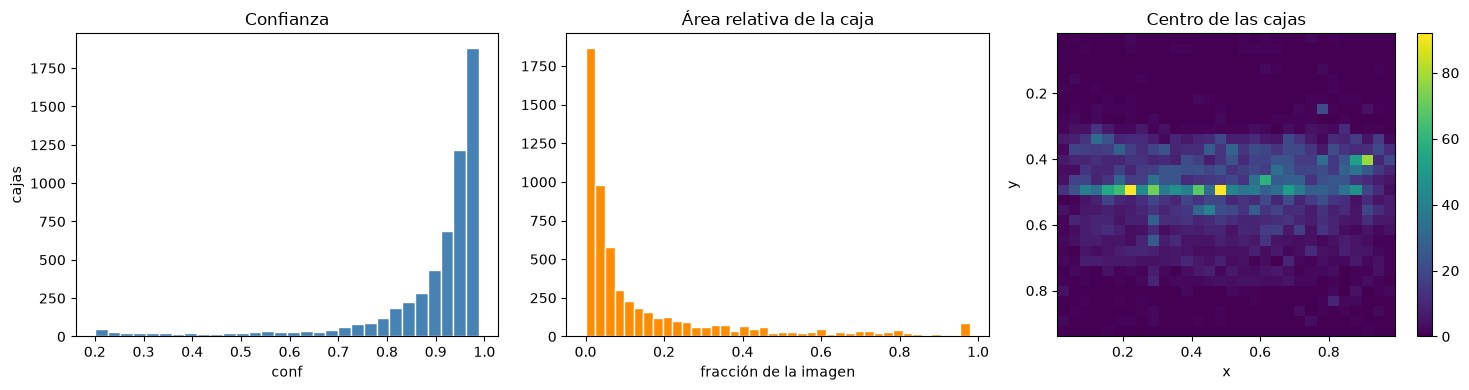

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(boxes["detectionConfidence"], bins=30, color="steelblue", edgecolor="white")
axes[0].set(title="Confianza", xlabel="conf", ylabel="cajas")

axes[1].hist(boxes["area"], bins=40, color="darkorange", edgecolor="white")
axes[1].set(title="Área relativa de la caja", xlabel="fracción de la imagen")

# Dónde aparecen los animales: la cámara trampa suele tener zonas "calientes" (sendero, comedero).
h = axes[2].hist2d(boxes["center_x"], boxes["center_y"], bins=30, cmap="viridis")
axes[2].invert_yaxis()  # y crece hacia abajo, como en la imagen
axes[2].set(title="Centro de las cajas", xlabel="x", ylabel="y")
fig.colorbar(h[3], ax=axes[2])
plt.tight_layout(); plt.show()

In [5]:
# Cajas por imagen: >1 en fotos de "un solo animal" suele ser falso positivo o error de etiqueta.
boxes_per_image = all_boxes.groupby("filePath").size()
print(boxes_per_image.value_counts().sort_index().head(8).rename("imágenes").to_frame().rename_axis("cajas por imagen"))
print(f"\nImágenes sin ninguna caja: {(labeled['detectionStatus'] == 'no_detection').sum()}")

                  imágenes
cajas por imagen          
1                     5080
2                      300
3                       26
4                        3
11                       1
13                       1

Imágenes sin ninguna caja: 31


## 2. Número de imágenes por clase: antes vs. después

- **Antes**: imágenes presentes en disco (mismo filtro que `dona_24_exploration.ipynb`) con una observación de animal, con familias fusionadas.
- **Filtro de un animal**: imágenes con una única observación y `count == 1` (`single_animal_images`).
- **Después**: las que además tienen caja de MegaDetector (`detectionStatus == "detected"`).

In [6]:
observations = pd.read_csv(PACKAGE_DIR / "observations.csv")
media = pd.read_csv(PACKAGE_DIR / "media.csv")

# Filtro de dona_24_exploration: solo imágenes descargadas en disco.
media_on_disk = media[media["filePath"].map(lambda path: (DATASET_DIR / path).exists())]
observations = observations[observations["mediaID"].isin(media_on_disk["mediaID"])]

animals = observations[(observations["observationLevel"] == "media") & (observations["observationType"] == "animal")]
animals['nombre_comun'] = animals['scientificName'].replace(FAMILY_OF_SPECIES).map(NOMBRE_COMUN).fillna('Desconocido')
animals = animals[animals['nombre_comun'] != 'Desconocido']
animals = animals.assign(className=animals["nombre_comun"])

# Se cuentan imágenes (mediaID únicos), no observaciones, para que las tres columnas sean comparables.
before = animals.groupby("className")["mediaID"].nunique().rename("antes")
single = labeled.groupby("className").size().rename("un_animal")
after = labeled[labeled["detectionStatus"] == "detected"].groupby("className").size().rename("después")

comparison = pd.concat([before, single, after], axis=1).fillna(0).astype(int).sort_values("antes", ascending=False)
comparison.loc["TOTAL"] = comparison.sum()
comparison["% conservado"] = (comparison["después"] / comparison["antes"] * 100).round(1)
comparison

,antes,un_animal,después,% conservado
className,,,,
Cérvido (ciervo/gamo),4355,2946,2925,67.2
Jabalí,1672,1236,1233,73.7
Vaca / Toro,1001,717,711,71.0
Lepórido (liebre/conejo),309,224,223,72.2
Zorro rojo,196,196,196,100.0
Tejón europeo,62,62,62,100.0
Caballo,37,32,32,86.5
Meloncillo,15,14,14,93.3
Gineta,10,10,10,100.0


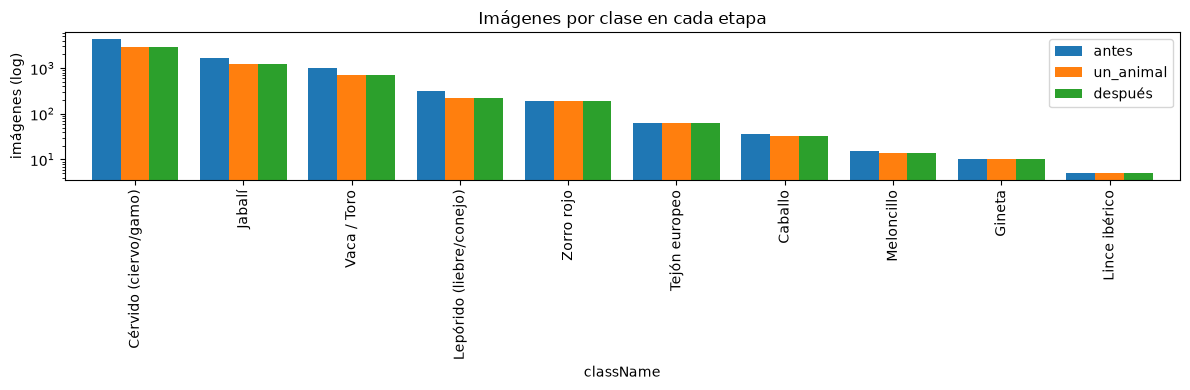

In [7]:
# Barras en escala log: las clases raras (lince, gineta...) desaparecerían en escala lineal.
comparison.drop(index="TOTAL")[["antes", "un_animal", "después"]].plot.bar(figsize=(12, 4), logy=True, width=.8)
plt.ylabel("imágenes (log)"); plt.title("Imágenes por clase en cada etapa"); plt.tight_layout(); plt.show()